# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from scipy.stats import normaltest
import math
from scipy.stats import kruskal, ttest_1samp
from scipy.stats import wilcoxon
from scipy.stats import mannwhitneyu, spearmanr, chi2_contingency

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

In [2]:
data = pd.read_csv("Bike Sales in Europe.csv") # Membaca file csv

In [3]:
df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame
df

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,1188,900,2088
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,238,180,418
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113031,2016-04-12,12,April,2016,41,Adults (35-64),M,United Kingdom,England,Clothing,Vests,"Classic Vest, S",3,24,64,112,72,184
113032,2014-04-02,2,April,2014,18,Youth (<25),M,Australia,Queensland,Clothing,Vests,"Classic Vest, M",22,24,64,655,528,1183
113033,2016-04-02,2,April,2016,18,Youth (<25),M,Australia,Queensland,Clothing,Vests,"Classic Vest, M",22,24,64,655,528,1183
113034,2014-03-04,4,March,2014,37,Adults (35-64),F,France,Seine (Paris),Clothing,Vests,"Classic Vest, L",24,24,64,684,576,1260


In [4]:
df.dtypes # Untuk mengetahui jumlah baris dan kolom. Mengetahui missing value tiap kolom, nama nama kolom, dan tipe data tiap kolom

Date                  str
Day                 int64
Month                 str
Year                int64
Customer_Age        int64
Age_Group             str
Customer_Gender       str
Country               str
State                 str
Product_Category      str
Sub_Category          str
Product               str
Order_Quantity      int64
Unit_Cost           int64
Unit_Price          int64
Profit              int64
Cost                int64
Revenue             int64
dtype: object

Dataset berisi **113.036 baris** transaksi dan **18 kolom**. Sembilan kolom berupa teks (Date, Month, Age_Group, Customer_Gender, Country, State, Product_Category, Sub_Category, Product) dan sembilan kolom berupa angka. Kolom Date masih berupa teks, jadi perlu diubah ke format tanggal sebelum dianalisis berdasarkan waktu.

In [5]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,Day,Year,Customer_Age,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
count,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000
mean,15.665753,2014.401739,35.919212,11.901660,267.296366,452.938427,285.051665,469.318695,754.370360
std,8.781567,1.272510,11.021936,9.561857,549.835483,922.071219,453.887443,884.866118,1309.094674
min,1.000000,2011.000000,17.000000,1.000000,1.000000,2.000000,-30.000000,1.000000,2.000000
25%,8.000000,2013.000000,28.000000,2.000000,2.000000,5.000000,29.000000,28.000000,63.000000
50%,16.000000,2014.000000,35.000000,10.000000,9.000000,24.000000,101.000000,108.000000,223.000000
75%,23.000000,2016.000000,43.000000,20.000000,42.000000,70.000000,358.000000,432.000000,800.000000
max,31.000000,2016.000000,87.000000,32.000000,2171.000000,3578.000000,15096.000000,42978.000000,58074.000000


- Data mencakup tahun **2011 sampai 2016**.
- Usia pelanggan 17 sampai 87 tahun dengan rata-rata sekitar 36 tahun. Separuh pelanggan berusia 28 sampai 43 tahun.
- Jumlah unit per transaksi 1 sampai 32, dengan median 10. Rentangnya lebar: seperempat transaksi hanya 2 unit atau kurang, seperempat lainnya 20 unit atau lebih.
- Kolom monetary (Unit_Cost, Unit_Price, Cost, Revenue, Profit) rata-ratanya **jauh di atas median**. Contohnya Unit_Price rata-rata 453 tetapi mediannya hanya 24. Artinya kebanyakan transaksi bernilai kecil, dan sedikit transaksi bernilai sangat besar menarik rata-ratanya ke atas.
- Revenue per transaksi paling kecil 2 dan paling besar 58.074 (median 223).

# Interpretasi data,masalah,rekomendasi

# Data Exploration

### Membuat Copy Dataset

In [6]:
df_copy = df.copy() # Membuat copy dataset

### Inkonsistensi Data (numerik & date)

In [7]:
inkonsistensi = df_copy.select_dtypes(include=["str"]).columns # Mengambil nama kolom dengan tipe data string

In [8]:
for i in inkonsistensi : # Memeriksa inkonsistensi data pada kolom dengan tipe data string
    print(f"Kolom {i} :")
    print(df_copy[i].unique())
    print("\n")

Kolom Date :
<ArrowStringArray>
['2013-11-26', '2015-11-26', '2014-03-23', '2016-03-23', '2014-05-15',
 '2016-05-15', '2014-05-22', '2016-05-22', '2014-02-22', '2016-02-22',
 ...
 '2012-09-06', '2011-09-06', '2012-01-07', '2011-01-07', '2012-10-27',
 '2011-10-27', '2013-01-06', '2015-01-06', '2012-02-20', '2011-02-20']
Length: 1884, dtype: str


Kolom Month :
<ArrowStringArray>
[ 'November',     'March',       'May',  'February',      'July',    'August',
 'September',   'January',  'December',      'June',   'October',     'April']
Length: 12, dtype: str


Kolom Age_Group :
<ArrowStringArray>
['Youth (<25)', 'Adults (35-64)', 'Young Adults (25-34)', 'Seniors (64+)']
Length: 4, dtype: str


Kolom Customer_Gender :
<ArrowStringArray>
['M', 'F']
Length: 2, dtype: str


Kolom Country :
<ArrowStringArray>
['Canada', 'Australia', 'United States', 'Germany', 'France',
 'United Kingdom']
Length: 6, dtype: str


Kolom State :
<ArrowStringArray>
[   'British Columbia',     'New South Wales',   

In [9]:
for i in inkonsistensi:
    print(i, ":", df_copy[i].str.strip().ne(df_copy[i]).sum())

Date : 0
Month : 0
Age_Group : 0
Customer_Gender : 0
Country : 0
State : 0
Product_Category : 0
Sub_Category : 0
Product : 0


In [10]:
for i in inkonsistensi:
    df_copy[i] = df_copy[i].str.strip()

Penulisan data sudah rapi dan tidak ada spasi berlebih

### Missing Value (Jumlah dan Persentase)

In [11]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [12]:
print(f"Jumlah missing value : \n{df_copy_miss}")
print(f"Persentase missing value : \n{df_copy_miss_percentage}")

Jumlah missing value : 
Date                0
Day                 0
Month               0
Year                0
Customer_Age        0
Age_Group           0
Customer_Gender     0
Country             0
State               0
Product_Category    0
Sub_Category        0
Product             0
Order_Quantity      0
Unit_Cost           0
Unit_Price          0
Profit              0
Cost                0
Revenue             0
dtype: int64
Persentase missing value : 
Date                0.0
Day                 0.0
Month               0.0
Year                0.0
Customer_Age        0.0
Age_Group           0.0
Customer_Gender     0.0
Country             0.0
State               0.0
Product_Category    0.0
Sub_Category        0.0
Product             0.0
Order_Quantity      0.0
Unit_Cost           0.0
Unit_Price          0.0
Profit              0.0
Cost                0.0
Revenue             0.0
dtype: float64


Tidak ada missing value di seluruh 18 kolom (0 baris atau 0%). Data sudah lengkap, jadi tidak perlu mengisi nilai kosong dan tidak ada baris yang dibuang karena alasan ini.

### Duplicate Value (Jumlah dan Persentase)

In [13]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
print(f"Jumlah Baris yang duplikat = {duplicate_all}")
print(f"Persentase Baris yang duplikat = {persent_duplicate_all:.2f}%")

Jumlah Baris yang duplikat = 1000
Persentase Baris yang duplikat = 0.88%


#### Menampilkan baris yang duplicate

In [14]:
dup_all = df_copy[df_copy.duplicated(keep=False)]
dup_all.sort_values(by=list(df_copy.columns)).head(10)

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
69018,2011-02-20,20,February,2011,25,Young Adults (25-34),F,Canada,British Columbia,Bikes,Road Bikes,"Road-250 Red, 52",1,1519,2443,900,1519,2419
69019,2011-02-20,20,February,2011,25,Young Adults (25-34),F,Canada,British Columbia,Bikes,Road Bikes,"Road-250 Red, 52",1,1519,2443,900,1519,2419
58238,2011-03-03,3,March,2011,43,Adults (35-64),F,United States,California,Bikes,Road Bikes,"Road-150 Red, 44",1,2171,3578,1335,2171,3506
58239,2011-03-03,3,March,2011,43,Adults (35-64),F,United States,California,Bikes,Road Bikes,"Road-150 Red, 44",1,2171,3578,1335,2171,3506
63340,2011-03-24,24,March,2011,24,Youth (<25),M,Australia,Victoria,Bikes,Road Bikes,"Road-250 Black, 44",1,1555,2443,375,1555,1930
63341,2011-03-24,24,March,2011,24,Youth (<25),M,Australia,Victoria,Bikes,Road Bikes,"Road-250 Black, 44",1,1555,2443,375,1555,1930
59240,2011-06-11,11,June,2011,42,Adults (35-64),F,United States,California,Bikes,Road Bikes,"Road-250 Black, 52",1,1555,2443,839,1555,2394
59241,2011-06-11,11,June,2011,42,Adults (35-64),F,United States,California,Bikes,Road Bikes,"Road-250 Black, 52",1,1555,2443,839,1555,2394
59820,2011-06-27,27,June,2011,37,Adults (35-64),M,United States,California,Bikes,Road Bikes,"Road-650 Red, 48",1,487,783,280,487,767
59821,2011-06-27,27,June,2011,37,Adults (35-64),M,United States,California,Bikes,Road Bikes,"Road-650 Red, 48",1,487,783,280,487,767


Ada **1.000 baris duplikat (0,88%)** dari 113.036 baris. Artinya seluruh 18 kolom pada baris tersebut sama persis dengan baris lain. Jumlahnya kecil, tetapi tetap perlu ditangani agar Revenue dan Profit tidak terhitung dua kali.

Pada 4 pasang baris yang ditampilkan, kedua baris kembarnya **berurutan** (misalnya baris 69018 dan 69019, atau 58238 dan 58239) dengan tanggal, usia, negara, produk, jumlah, harga, dan revenue yang sama persis. Baris kembar yang saling bersebelahan seperti ini lebih mirip **input ganda** daripada dua pembelian terpisah, karena dua pembelian terpisah jarang tercatat tepat berurutan dengan data identik. Itulah alasan baris tersebut dihapus dan hanya satu salinan yang disimpan.

### Encoder Kolom Kategori Untuk Periksa Outlier

### Encoder

In [15]:
le = LabelEncoder()

In [16]:
df_copy["Date_code"] = le.fit_transform(df_copy["Date"])
df_copy["Month_code"] = le.fit_transform(df_copy["Month"])
df_copy["Age_Group_code"] = le.fit_transform(df_copy["Age_Group"])
df_copy["Customer_Gender_code"] = le.fit_transform(df_copy["Customer_Gender"])
df_copy["Country_code"] = le.fit_transform(df_copy["Country"])
df_copy["State_code"] = le.fit_transform(df_copy["State"])
df_copy["Product_Category_code"] = le.fit_transform(df_copy["Product_Category"])
df_copy["Sub_Category_code"] = le.fit_transform(df_copy["Sub_Category"])
df_copy["Product_code"] = le.fit_transform(df_copy["Product"])

In [17]:
df_copy

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,...,Revenue,Date_code,Month_code,Age_Group_code,Customer_Gender_code,Country_code,State_code,Product_Category_code,Sub_Category_code,Product_code
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,...,950,1059,9,3,1,1,5,0,0,12
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,...,950,1636,9,3,1,1,5,0,0,12
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,...,2401,1176,7,0,1,0,26,0,0,12
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,...,2088,1753,7,0,1,0,26,0,0,12
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,...,418,1229,8,0,0,0,26,0,0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113031,2016-04-12,12,April,2016,41,Adults (35-64),M,United Kingdom,England,Clothing,...,184,1773,0,0,1,4,8,2,16,5
113032,2014-04-02,2,April,2014,18,Youth (<25),M,Australia,Queensland,Clothing,...,1183,1186,0,3,1,0,35,2,16,4
113033,2016-04-02,2,April,2016,18,Youth (<25),M,Australia,Queensland,Clothing,...,1183,1763,0,3,1,0,35,2,16,4
113034,2014-03-04,4,March,2014,37,Adults (35-64),F,France,Seine (Paris),Clothing,...,1260,1157,7,0,0,2,37,2,16,3


In [18]:
describe_label = df_copy[["Date_code","Month_code","Age_Group_code","Customer_Gender_code",
                          "Country_code","State_code","Product_Category_code","Sub_Category_code","Product_code"]].copy()

In [19]:
describe_label.describe()

,Date_code,Month_code,Age_Group_code,Customer_Gender_code,Country_code,State_code,Product_Category_code,Sub_Category_code,Product_code
count,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000,113036.000000
mean,1348.473831,5.415885,1.163541,0.515871,2.830762,21.834654,0.529477,9.342970,59.143529
std,375.481105,3.410702,1.199987,0.499750,1.996016,16.862572,0.740782,4.516857,41.235546
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1085.000000,2.000000,0.000000,0.000000,1.000000,6.000000,0.000000,6.000000,22.000000
50%,1272.000000,6.000000,1.000000,1.000000,3.000000,15.000000,0.000000,10.000000,53.000000
75%,1680.000000,8.000000,2.000000,1.000000,5.000000,36.000000,1.000000,14.000000,100.000000
max,1883.000000,11.000000,3.000000,1.000000,5.000000,52.000000,2.000000,16.000000,129.000000


### Outlier

In [20]:
cek_outlier = df_copy.select_dtypes(include=["int64"]).columns
cek_outlier

Index(['Day', 'Year', 'Customer_Age', 'Order_Quantity', 'Unit_Cost',
       'Unit_Price', 'Profit', 'Cost', 'Revenue', 'Date_code', 'Month_code',
       'Age_Group_code', 'Customer_Gender_code', 'Country_code', 'State_code',
       'Product_Category_code', 'Sub_Category_code', 'Product_code'],
      dtype='str')

In [21]:
summary_data = []
kolom_dengan_outlier = []

for i in cek_outlier:
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum()
    persentase_outlier = (jumlah_outlier / len(outlier)) * 100
    
    # Simpan data ke dalam list untuk dibuat DataFrame nanti
    summary_data.append({
        'Kolom': i,
        'Jumlah Outlier': jumlah_outlier,
        'Persentase (%)': persentase_outlier
    })
    
    # Cek apakah kolom ini memiliki outlier (> 0)
    if jumlah_outlier > 0:
        kolom_dengan_outlier.append(df_copy[i])

df_outlier_summary = pd.DataFrame(summary_data).sort_values(by=("Jumlah Outlier"), ascending=False)

display(df_outlier_summary)

,Kolom,Jumlah Outlier,Persentase (%)
4,Unit_Cost,25984,22.987367
5,Unit_Price,25984,22.987367
7,Cost,18179,16.082487
8,Revenue,14765,13.062210
6,Profit,10021,8.865317
9,Date_code,1294,1.144768
2,Customer_Age,534,0.472416
12,Customer_Gender_code,0,0.000000
16,Sub_Category_code,0,0.000000
15,Product_Category_code,0,0.000000


Terdapat Outlier terhadap variabel numerik, seperti harga barang (Unit price), biaya produksi (Unit cost), dan umur (age), 
secara alami dapat memiliki rentang nilai yang cukup luas. Perbedaan karakteristik produk, skala produksi, 
segmentasi pasar, serta kondisi individu dapat menyebabkan variasi nilai yang signifikan.

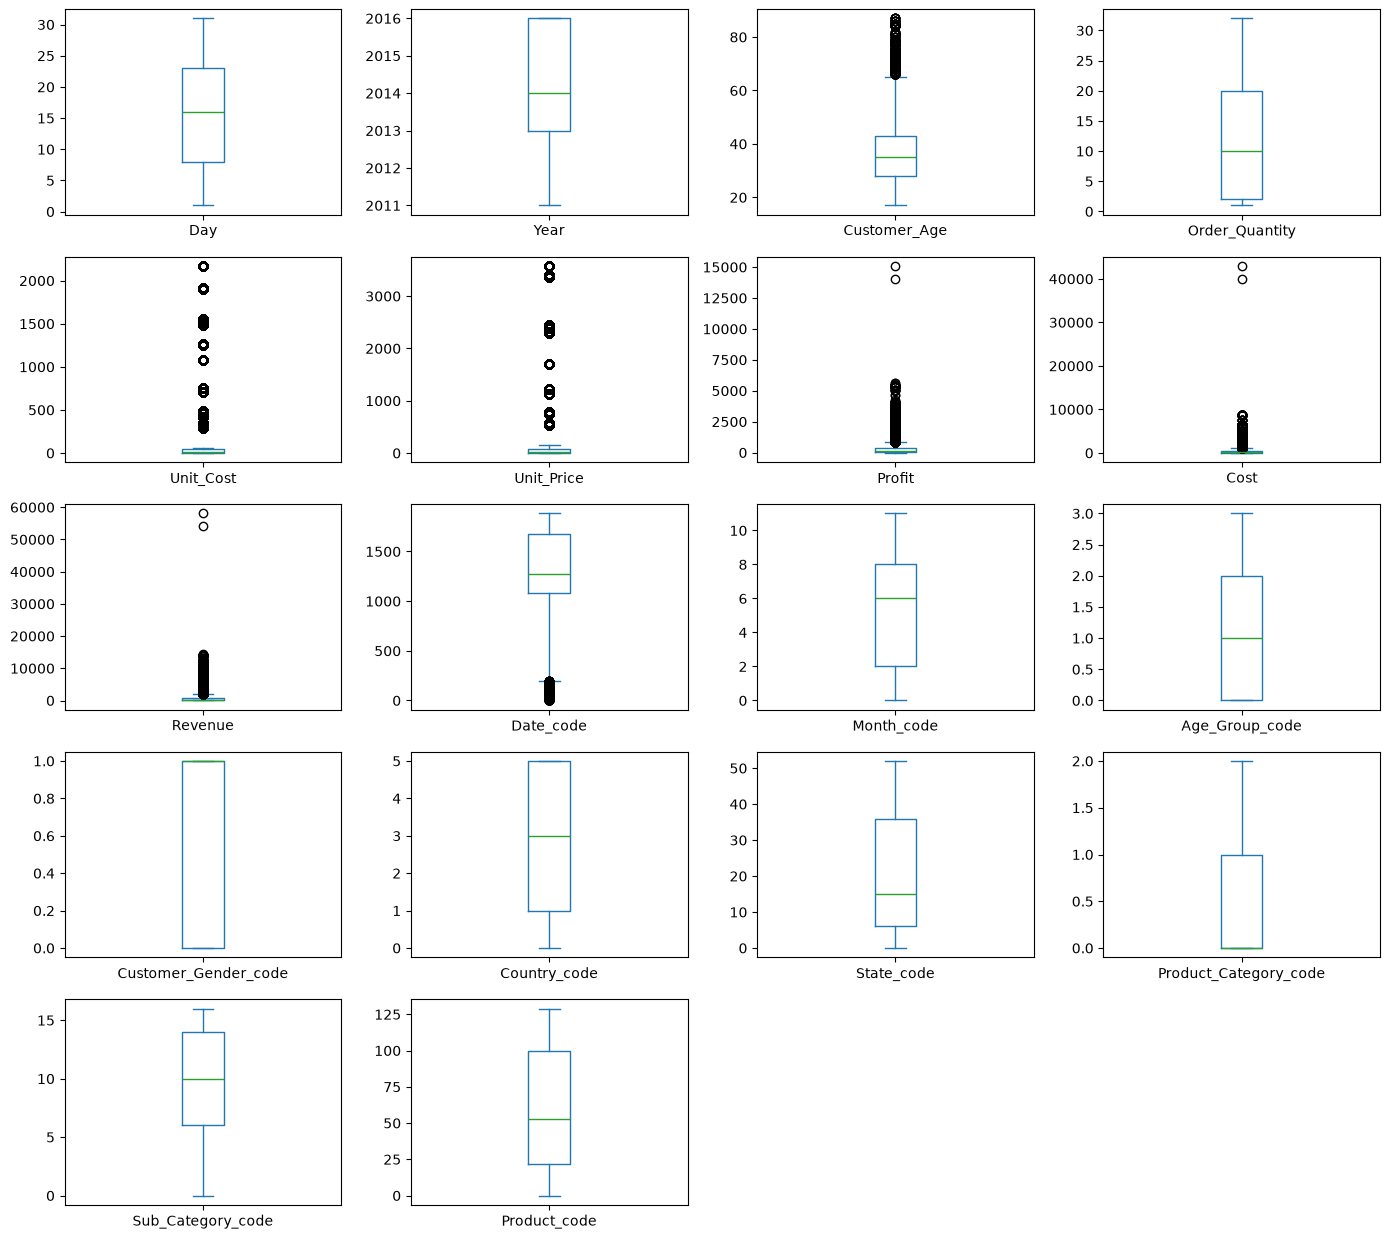

In [22]:
n_cols = 4
n_rows = math.ceil(len(cek_outlier) / n_cols)

df_copy[cek_outlier].plot(
    kind="box",
    subplots=True,
    layout=(n_rows, n_cols),
    figsize=(14, n_rows * 2.5),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

- **Unit_Cost dan Unit_Price:** titik outlier tersusun berlapis seperti garis-garis horizontal. Tiap lapisan adalah harga tetap dari produk tertentu, bukan angka acak, jadi ini produk mahal tertentu dan bukan salah input.
- **Profit, Cost, dan Revenue:** hampir semua transaksi menumpuk di bagian bawah, dan ada **dua titik yang sangat jauh di atas** (Revenue sekitar 54.000 dan 58.000, Cost sekitar 40.000 dan 43.000, Profit sekitar 14.000 dan 15.000).
- **Day, Year, dan Order_Quantity** tidak punya titik di luar kotak, jadi sebarannya wajar.

In [23]:
for i in cek_outlier :
    statistic, p_value = normaltest(df_copy[i])

    print(f"Kolom {i}")
    print("Statistic:", statistic)
    print("P-value:", p_value)

    alpha = 0.05

    if p_value < alpha:
        print("Tolak H0: Data tidak berdistribusi normal")
    else:
        print("Gagal menolak H0: Tidak cukup bukti bahwa data tidak normal")
    print("\n")

Kolom Day
Statistic: 91608.21826661212
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Year
Statistic: 4737.980892020187
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Customer_Age
Statistic: 4682.775094351195
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Order_Quantity
Statistic: 141517.81180588447
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Unit_Cost
Statistic: 44201.09411552087
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Unit_Price
Statistic: 43300.323456799764
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Profit
Statistic: 99787.04681205883
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Cost
Statistic: 124078.617189278
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Revenue
Statistic: 116100.02000817074
P-value: 0.0
Tolak H0: Data tidak berdistribusi normal


Kolom Date_code
Statistic: 8184.68080091422
P-value: 0.0
Tolak H0: Data tidak berdistribusi 

Pada **semua 18 kolom** p-value bernilai 0,0 (lebih kecil dari 0,05), sehingga hipotesis "data tidak berdistri normal" yang nantinya akan mempengaruhi pemilihan penggunaan model untuk analisa kedepannya

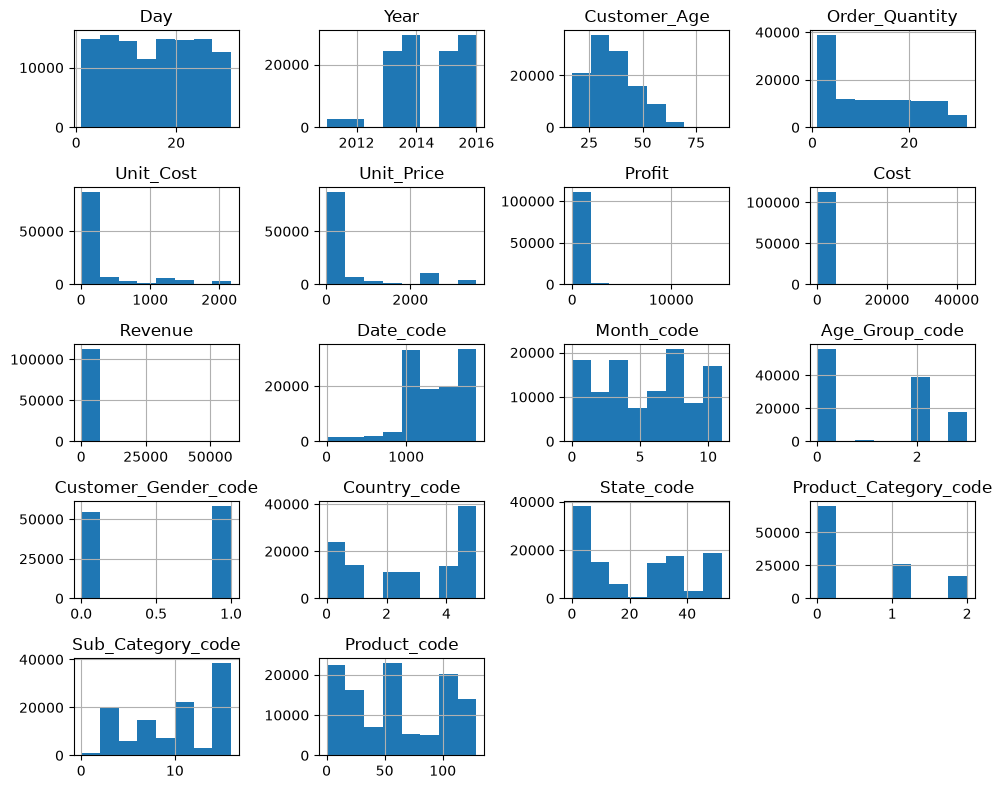

In [24]:
df_copy[cek_outlier].hist(
    bins=8,
    figsize=(10, 8)
)

plt.tight_layout()
plt.show()

- **Day:** transaksi tersebar merata sepanjang bulan, tidak ada tanggal yang menonjol.
- **Year:** data 2013 sampai 2016 masing-masing sekitar 24 sampai 30 ribu transaksi.
- **Customer_Age:** paling banyak pelanggan berusia sekitar 25 sampai 35 tahun, usia bertambah jumlah menjadi pelanggannya juga berkurang
- **Order_Quantity:** paling banyak transaksi berjumlah kecil (1 sampai 4 unit, sekitar sepertiga data), sisanya tersebar cukup rata, dan jumlah terbesar (sekitar 29 sampai 32 unit) paling jarang.
- **Unit_Cost dan Unit_Price:** sekitar 87 ribu transaksi (sekitar 77%) berharga murah, lalu ada kelompok kecil di kisaran 2.400 dan 3.500. Ini menunjukkan ada dua dunia produk: banyak produk murah dan sedikit produk mahal.
- **Profit, Cost, dan Revenue:** hampir semua transaksi berada di nilai kecil dengan ekor sangat panjang ke kanan (miring ke kanan).
- **Gender (kode 1 = M):** pelanggan laki-laki sedikit lebih banyak (sekitar 52%).
- **Age_Group:** kelompok Adults (35-64) terbesar (sekitar separuh data), disusul Young Adults, lalu Youth. Kelompok Seniors (64+) sangat sedikit (sekitar 1 ribu).
- **Country:** United States paling banyak (sekitar 39 ribu, sepertiga data), disusul Australia (sekitar 24 ribu). Canada dan United Kingdom sekitar 14 ribu, France dan Germany sekitar 11 ribu.
- **Product_Category:** Accessories paling banyak (sekitar 70 ribu, lebih dari separuh), lalu Bikes (sekitar 25 ribu) dan Clothing (sekitar 17 ribu).

Berdasarkan hasil analisis, aktivitas transaksi selama 2013–2016 relatif stabil dan tersebar merata sepanjang bulan. Mayoritas pelanggan berada pada rentang usia produktif, khususnya Adults (35–64 tahun), dengan pelanggan laki-laki sedikit lebih dominan (52%). Dari sisi penjualan, sebagian besar pelanggan melakukan pembelian dalam jumlah kecil (1–4 unit), dengan produk berharga rendah mendominasi transaksi (77%). Accessories menjadi kategori produk paling diminati, disusul Bikes dan Clothing. Sementara itu, Profit, Cost, dan Revenue menunjukkan distribusi right-skewed, yang berarti sebagian besar transaksi bernilai kecil, tetapi terdapat sejumlah kecil transaksi dengan nilai tinggi. United States dan Australia menjadi pasar dengan jumlah transaksi terbesar. Untuk mengoptimalkan penjualan, perusahaan disarankan mempertahankan pelanggan utama melalui program loyalitas, meningkatkan jumlah pembelian melalui strategi bundling dan cross-selling, menjaga ketersediaan stok produk terlaris, serta mengembangkan pemasaran berdasarkan karakteristik usia dan negara. Selain itu, perusahaan perlu mengevaluasi transaksi bernilai tinggi untuk mengidentifikasi produk dan pelanggan yang memberikan kontribusi profit terbesar.

### Distribusi Data

#### Heatmap

In [25]:
numerik = df_copy.select_dtypes(include=("int64"))

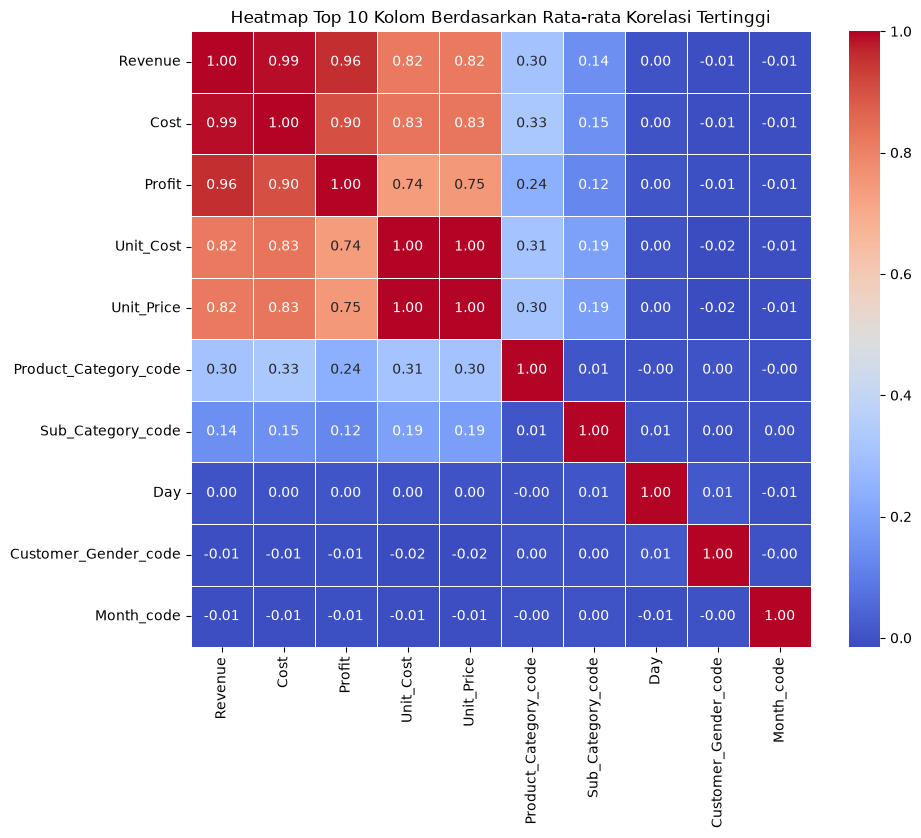

In [26]:
top_corr_cols = numerik.corr().mean().nlargest(10).index
corr_top = numerik[top_corr_cols].corr()

# Plot heatmap 10x10
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Top 10 Kolom Berdasarkan Rata-rata Korelasi Tertinggi")
plt.show()

# Data Preparation

## Data Cleaning

### Penanganan Datetime

In [27]:
df_copy["Date"] = pd.to_datetime(df_copy["Date"], errors="coerce")

In [58]:
df_copy.dtypes

Date                     datetime64[us]
Day                               int64
Month                               str
Year                              int64
Customer_Age                      int64
Age_Group                           str
Customer_Gender                     str
Country                             str
State                               str
Product_Category                    str
Sub_Category                        str
Product                             str
Order_Quantity                    int64
Unit_Cost                         int64
Unit_Price                        int64
Date_code                         int64
Month_code                        int64
Age_Group_code                    int64
Customer_Gender_code              int64
Country_code                      int64
State_code                        int64
Product_Category_code             int64
Sub_Category_code                 int64
Product_code                      int64
Total_Cost                        int64


In [29]:
df_copy["Date"].isna().sum()

np.int64(0)

### Penanganan duplicate

In [30]:
df_copy = df_copy.drop_duplicates()
df_copy.duplicated().sum()

np.int64(0)

In [31]:
print(f"Jumlah duplicate : {df_copy.duplicated().sum()}")
print(f"Persentase duplicate : {df_copy.duplicated().mean() * 100:.2f}%")

Jumlah duplicate : 0
Persentase duplicate : 0.00%


1.000 baris kembar sudah dihapus dan sisanya **0 duplikat**. Data tinggal **112.036 baris** (113.036 dikurangi 1.000). Karena yang dihapus hanya 0,88% dan sifatnya salinan identik, bentuk data secara keseluruhan tidak berubah.

### Penanganan Kolom ['Profit', 'Cost', 'Revenue']

#### Sebelum menghitung ulang

In [32]:
df.head(5)

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Profit,Cost,Revenue
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,590,360,950
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1366,1035,2401
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,1188,900,2088
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,238,180,418


### Feature Engineering

#### Penanganan menghitung ulang

In [33]:
df_copy = df_copy.drop(['Profit', 'Cost', 'Revenue'], axis =1)

In [34]:
df_copy['Total_Cost'] = df_copy['Order_Quantity'] * df_copy['Unit_Cost']
df_copy['Revenue'] = df_copy['Order_Quantity'] * df_copy['Unit_Price']
df_copy['Profit'] = df_copy['Revenue'] - df_copy['Total_Cost']

In [35]:
df_copy[["Profit", "Total_Cost", "Revenue"]].head(5)

,Profit,Total_Cost,Revenue
0,600,360,960
1,600,360,960
2,1725,1035,2760
3,1500,900,2400
4,300,180,480


Setelah dilakukannya perhitungan ulang

In [36]:
df[["Profit", "Cost", "Revenue"]].head(5)

,Profit,Cost,Revenue
0,590,360,950
1,590,360,950
2,1366,1035,2401
3,1188,900,2088
4,238,180,418


Sebelum dilakukannya perhitungan ulang

Kolom baru yang sudah dilakukan perhitungan ulang:

In [37]:
df_copy.head(5)

,Date,Day,Month,Year,Customer_Age,Age_Group,Customer_Gender,Country,State,Product_Category,...,Age_Group_code,Customer_Gender_code,Country_code,State_code,Product_Category_code,Sub_Category_code,Product_code,Total_Cost,Revenue,Profit
0,2013-11-26,26,November,2013,19,Youth (<25),M,Canada,British Columbia,Accessories,...,3,1,1,5,0,0,12,360,960,600
1,2015-11-26,26,November,2015,19,Youth (<25),M,Canada,British Columbia,Accessories,...,3,1,1,5,0,0,12,360,960,600
2,2014-03-23,23,March,2014,49,Adults (35-64),M,Australia,New South Wales,Accessories,...,0,1,0,26,0,0,12,1035,2760,1725
3,2016-03-23,23,March,2016,49,Adults (35-64),M,Australia,New South Wales,Accessories,...,0,1,0,26,0,0,12,900,2400,1500
4,2014-05-15,15,May,2014,47,Adults (35-64),F,Australia,New South Wales,Accessories,...,0,0,0,26,0,0,12,180,480,300


Dilakukannya perhitungan ulang dikarenakan saya ber asumsi kalau data sebelumnya salah untuk perhitungannya.
Dataset juga tidak memberikan penjelasan untuk mengenai potongan seperti diskon, maka dari itu saya melakukan perhitungan ulang pada kolom tersebut

### Penanganan Outlier

Outlier **tidak** ditangani
Alasan:
- Nilai Revenue atau Profit yang tinggi belum tentu salah, karena pesanan besar dan produk mahal memang ada.

**Insight Akhir (Kondisi Data Setelah Data Preparation & Cleaning):**

- Data siap dianalisis: **112.036 baris**, 0 missing value, 0 duplikat, dan semua tanggal valid.
- Label teks konsisten (tidak ada spasi berlebih atau label ganda).
- Revenue dan Profit dihitung ulang (Total_Cost = Order_Quantity x Unit_Cost, Revenue = Order_Quantity x Unit_Price, Profit = Revenue - Total_Cost).
- Outlier pada kolom uang dipertahankan karena itu produk dan pesanan bernilai besar yang memang ada.

# EDA

### 1. Revenue & Profit Based on Country

In [38]:
country_sales = df_copy.groupby("Country").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Order_Quantity", "sum")
).sort_values("Total_Revenue", ascending=False)

display(country_sales)

,Total_Revenue,Total_Profit,Total_Quantity
Country,,,
United States,30599566,13820106,473880
Australia,25303706,10847833,261227
United Kingdom,11016494,4824853,155769
Germany,9958420,4351687,124755
France,9825708,4283045,127872
Canada,7984694,3780531,190202


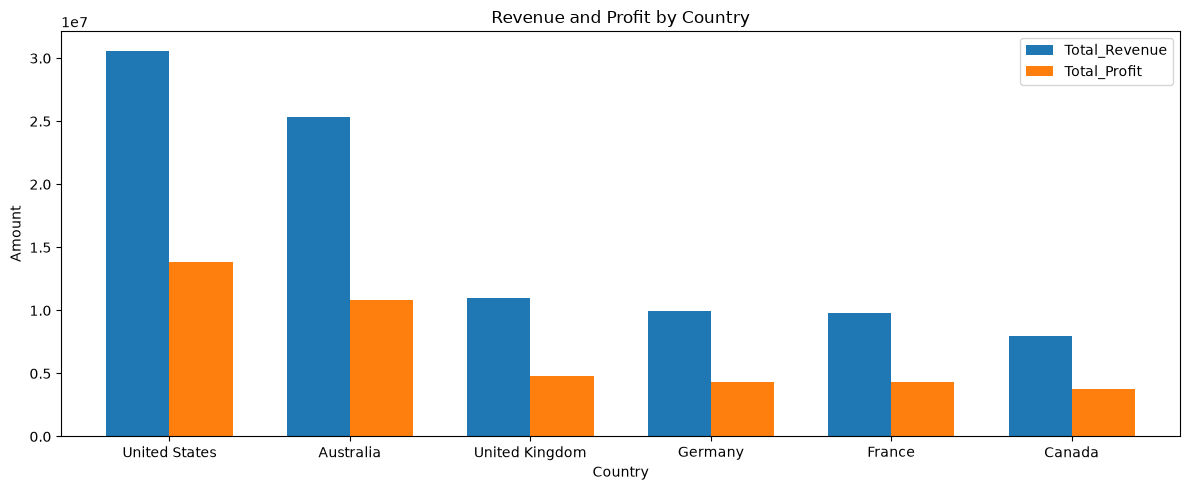

In [39]:
country_sales[["Total_Revenue", "Total_Profit"]].plot(
    kind="bar",
    figsize=(12, 5),
    width=0.7
)

plt.title("Revenue and Profit by Country")
plt.xlabel("Country")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Chart ini menunjukkan perbandingan total Revenue dan Profit dari setiap negara untuk mengetahui pasar yang memberikan kontribusi terbesar terhadap bisnis. Perbandingan keduanya juga membantu melihat apakah negara dengan pendapatan tertinggi mampu menghasilkan keuntungan yang sebanding.

Setelah mengetahui performa bisnis di setiap negara, selanjutnya kita akan melihat wilayah atau state mana yang memberikan kontribusi pendapatan terbesar.

### 2. Top 5 State Based on Revenue

In [40]:
top_state = (
    df_copy.groupby("State")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

display(top_state.to_frame("Total_Revenue"))

,Total_Revenue
State,
California,17887092
England,11016494
New South Wales,10489298
Washington,8590886
British Columbia,7926676


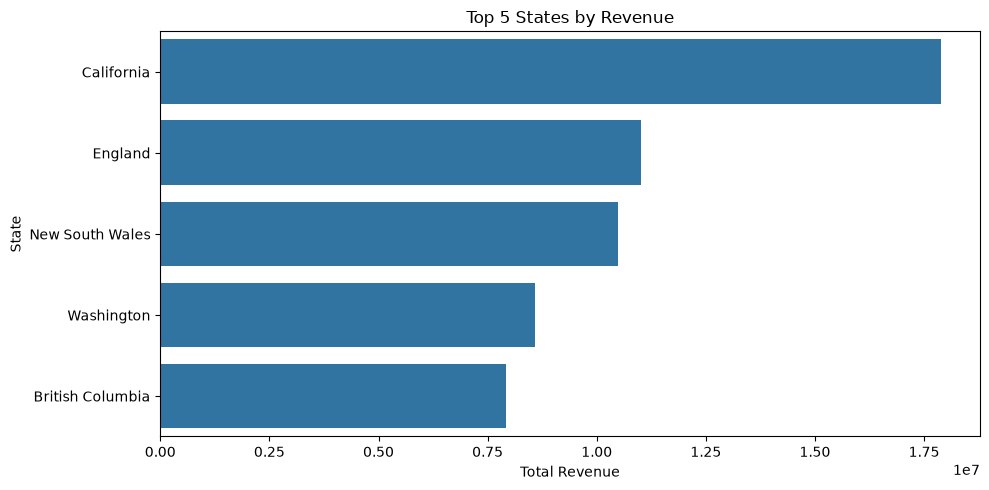

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_state.values,
    y=top_state.index
)

plt.title("Top 5 States by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("State")
plt.tight_layout()
plt.show()

Chart ini menampilkan lima state dengan total Revenue tertinggi untuk mengidentifikasi wilayah yang memiliki potensi pasar paling besar. Informasi ini dapat membantu perusahaan memahami area yang perlu dipertahankan atau dikembangkan untuk meningkatkan penjualan.

Setelah mengetahui wilayah dengan pendapatan tertinggi, kita akan beralih melihat kategori produk yang menjadi penyumbang utama Revenue perusahaan.

### 3. Revenue & Percentage Based on Product Category

In [42]:
category_sales = df_copy.groupby("Product_Category")["Revenue"].sum().reset_index()

category_sales["Percentage"] = (
    category_sales["Revenue"] /
    category_sales["Revenue"].sum()
) * 100

category_sales = category_sales.sort_values(
    "Revenue", ascending=False
)

display(category_sales)

,Product_Category,Revenue,Percentage
1,Bikes,68827927,72.688725
0,Accessories,16606777,17.538309
2,Clothing,9253884,9.772967


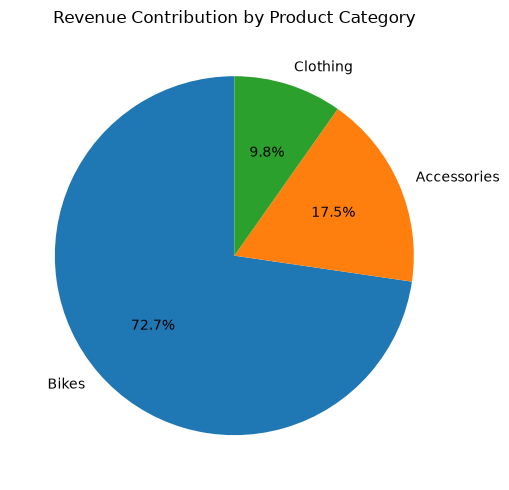

In [43]:
plt.figure(figsize=(9, 5))

plt.pie(
    category_sales["Revenue"],
    labels=category_sales["Product_Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Contribution by Product Category")
plt.tight_layout()
plt.show()

Chart ini menunjukkan kontribusi masing-masing Product Category terhadap total Revenue. Dari sini, kita dapat mengetahui kategori produk yang paling dominan dan seberapa besar ketergantungan pendapatan perusahaan terhadap kategori tersebut.

Setelah mengetahui kategori produk yang menghasilkan pendapatan terbesar, selanjutnya kita akan melihat karakteristik pelanggan berdasarkan kelompok usia dan gender.

### 4. Revenue Based on Age Group and Gender

In [44]:
age_gender = df_copy.groupby(
    ["Age_Group", "Customer_Gender"]
)["Revenue"].sum().reset_index()

display(age_gender)

,Age_Group,Customer_Gender,Revenue
0,Adults (35-64),F,23497937
1,Adults (35-64),M,23588903
2,Seniors (64+),F,140683
3,Seniors (64+),M,197973
4,Young Adults (25-34),F,16932345
5,Young Adults (25-34),M,17172107
6,Youth (<25),F,6008650
7,Youth (<25),M,7149990


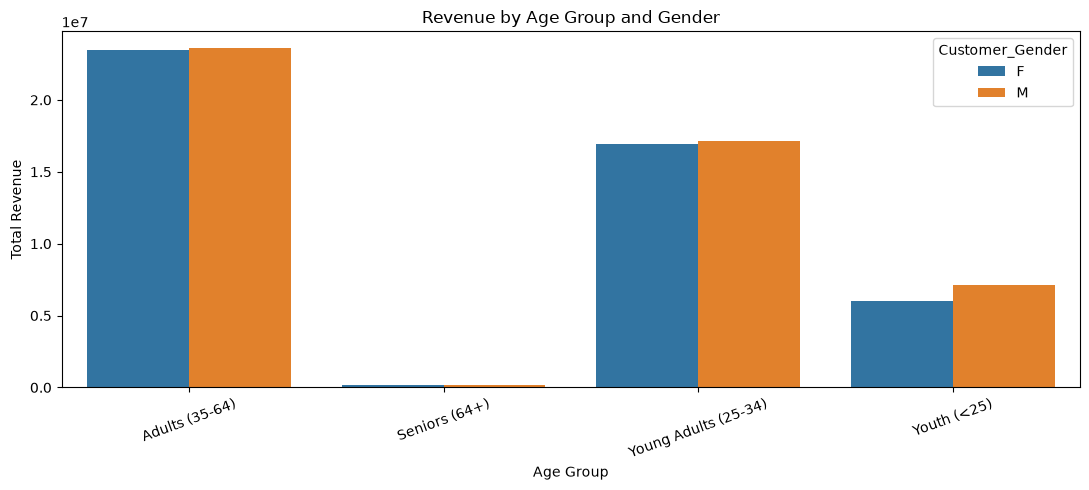

In [45]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=age_gender,
    x="Age_Group",
    y="Revenue",
    hue="Customer_Gender"
)

plt.title("Revenue by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Chart ini membandingkan total Revenue berdasarkan Age Group dan Gender untuk mengetahui kelompok pelanggan yang memberikan kontribusi pendapatan terbesar. Hasilnya dapat membantu perusahaan memahami karakteristik pelanggan dan menentukan target pasar yang lebih tepat.

Selain mengetahui kelompok pelanggan yang menghasilkan pendapatan terbesar, penting juga untuk memahami kategori produk yang berkontribusi pada setiap kelompok usia.

### 5. Revenue Based on Age Group and Product Category

In [46]:
age_product = df_copy.groupby(
    ["Age_Group", "Product_Category"]
)["Revenue"].sum().reset_index()

display(age_product)

,Age_Group,Product_Category,Revenue
0,Adults (35-64),Accessories,8592030
1,Adults (35-64),Bikes,33636771
2,Adults (35-64),Clothing,4858039
3,Seniors (64+),Accessories,134801
4,Seniors (64+),Bikes,149794
5,Seniors (64+),Clothing,54061
6,Young Adults (25-34),Accessories,5519201
7,Young Adults (25-34),Bikes,25548665
8,Young Adults (25-34),Clothing,3036586
9,Youth (<25),Accessories,2360745


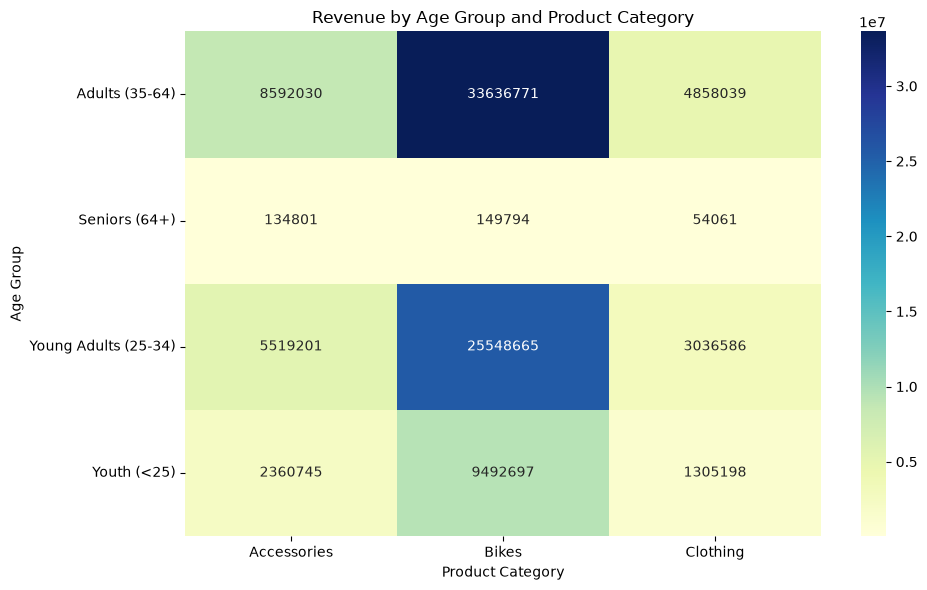

In [47]:
pivot_age_product = age_product.pivot(
    index="Age_Group",
    columns="Product_Category",
    values="Revenue"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_age_product,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Revenue by Age Group and Product Category")
plt.xlabel("Product Category")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()

Chart ini menunjukkan hubungan antara kelompok usia pelanggan dan Product Category berdasarkan total Revenue. Melalui perbandingan ini, perusahaan dapat melihat kategori produk yang memberikan kontribusi terbesar pada setiap kelompok usia dan memahami perbedaan kebutuhan pelanggan.

Meskipun suatu kategori produk menghasilkan Revenue yang tinggi, hal tersebut belum tentu menunjukkan keuntungan yang tinggi. Oleh karena itu, analisis selanjutnya akan berfokus pada Profit Margin setiap kategori produk.

### 6. Profit Margin Based on Product Category

In [48]:
category_profit = df_copy.groupby("Product_Category").agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum")
)

category_profit["Profit_Margin"] = (
    category_profit["Profit"] /
    category_profit["Revenue"]
) * 100

display(category_profit.sort_values("Profit_Margin", ascending=False))

,Revenue,Profit,Profit_Margin
Product_Category,,,
Accessories,16606777,10391205,62.572075
Bikes,68827927,27793169,40.380657
Clothing,9253884,3723681,40.239115


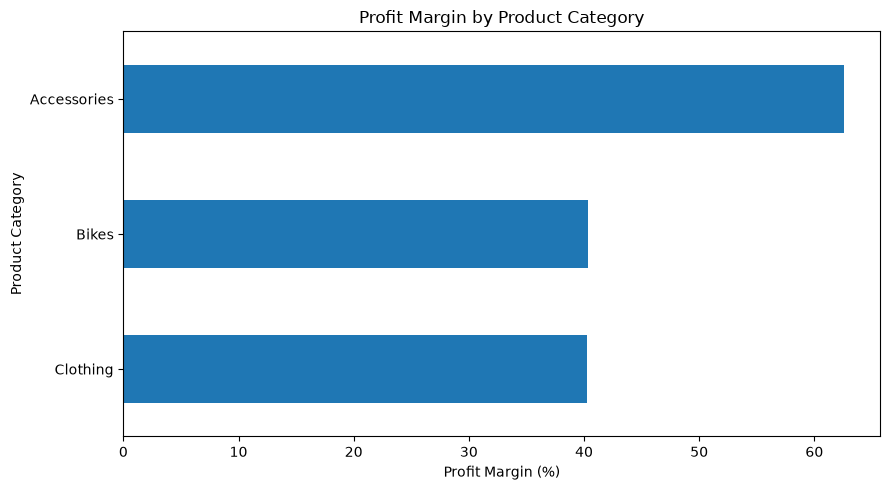

In [49]:
category_profit["Profit_Margin"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

Chart ini membandingkan Profit Margin dari setiap Product Category untuk mengetahui kategori yang mampu menghasilkan keuntungan paling besar dibandingkan pendapatannya. Analisis ini penting karena perusahaan tidak hanya perlu meningkatkan penjualan, tetapi juga memastikan bahwa penjualan tersebut memberikan keuntungan yang optimal.

Berdasarkan seluruh analisis, perusahaan dapat memahami pasar potensial, wilayah dengan kontribusi pendapatan terbesar, kategori produk unggulan, serta karakteristik pelanggan.

### 7. Average Order Quantity Based on Age Group

In [50]:
age_quantity = df_copy.groupby("Age_Group").agg(
    Average_Quantity=("Order_Quantity", "mean"),
    Total_Quantity=("Order_Quantity", "sum")
)

display(age_quantity)

,Average_Quantity,Total_Quantity
Age_Group,,
Adults (35-64),12.050616,667098
Seniors (64+),13.500695,9707
Young Adults (25-34),11.566281,442977
Youth (<25),12.113420,213923


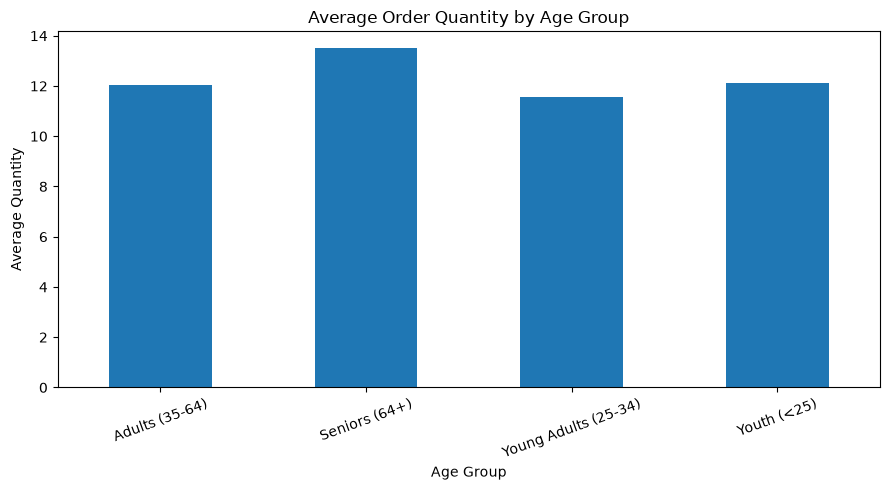

In [51]:
age_quantity["Average_Quantity"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Order Quantity by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Quantity")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Uji Statistik

In [52]:
# Memilih kolom yang digunakan untuk EDA
kolom_eda = [
    "Customer_Age", "Customer_Gender", "Age_Group",
    "Country", "State",
    "Product_Category", "Sub_Category", "Product",
    "Order_Quantity", "Unit_Cost", "Unit_Price",
    "Total_Cost", "Revenue", "Profit"
]

# Mengambil hanya kolom yang tersedia di dataset
kolom_eda = [col for col in kolom_eda if col in df_copy.columns]
eda = df_copy[kolom_eda].copy()

# Memisahkan kolom kategorikal dan numerik
kolom_kategori = eda.select_dtypes(include=["object", "category"]).columns.tolist()
kolom_numerik = eda.select_dtypes(include=np.number).columns.tolist()

print("Jumlah baris dan kolom:", eda.shape)
print("\nKolom kategorikal:", kolom_kategori)
print("\nKolom numerik:", kolom_numerik)
display(eda.head())

Jumlah baris dan kolom: (112036, 14)

Kolom kategorikal: ['Customer_Gender', 'Age_Group', 'Country', 'State', 'Product_Category', 'Sub_Category', 'Product']

Kolom numerik: ['Customer_Age', 'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Total_Cost', 'Revenue', 'Profit']


/var/folders/kt/j8z_mc1x3b7_vrddr130xwb80000gn/T/ipykernel_38950/3480431891.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolom_kategori = eda.select_dtypes(include=["object", "category"]).columns.tolist()


,Customer_Age,Customer_Gender,Age_Group,Country,State,Product_Category,Sub_Category,Product,Order_Quantity,Unit_Cost,Unit_Price,Total_Cost,Revenue,Profit
0,19,M,Youth (<25),Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,360,960,600
1,19,M,Youth (<25),Canada,British Columbia,Accessories,Bike Racks,Hitch Rack - 4-Bike,8,45,120,360,960,600
2,49,M,Adults (35-64),Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,23,45,120,1035,2760,1725
3,49,M,Adults (35-64),Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,20,45,120,900,2400,1500
4,47,F,Adults (35-64),Australia,New South Wales,Accessories,Bike Racks,Hitch Rack - 4-Bike,4,45,120,180,480,300


## 7.1 Kruskal–Wallis: Perbedaan Revenue antar Kelompok Usia

- **H0:** Distribusi Revenue sama pada seluruh kelompok usia.
- **H1:** Setidaknya ada satu kelompok usia dengan distribusi Revenue yang berbeda.

In [53]:
if "Age_Group" in eda.columns and "Revenue" in eda.columns:
    data_usia = [
        grup["Revenue"].dropna().values
        for _, grup in eda.groupby("Age_Group")
        if grup["Revenue"].notna().sum() > 0
    ]
    nama_usia = [
        nama for nama, grup in eda.groupby("Age_Group")
        if grup["Revenue"].notna().sum() > 0
    ]

    if len(data_usia) >= 2:
        h_stat, p_value = kruskal(*data_usia)
        print("Kelompok usia:", nama_usia)
        print("Kruskal-Wallis H:", h_stat)
        print("P-value:", p_value)

        if p_value < alpha:
            print("Keputusan: Tolak H0. Ada perbedaan distribusi Revenue pada setidaknya dua kelompok usia.")
        else:
            print("Keputusan: Gagal menolak H0. Belum ada bukti perbedaan distribusi Revenue antar kelompok usia.")

Kelompok usia: ['Adults (35-64)', 'Seniors (64+)', 'Young Adults (25-34)', 'Youth (<25)']
Kruskal-Wallis H: 554.7216598637771
P-value: 6.583858477861343e-120
Keputusan: Tolak H0. Ada perbedaan distribusi Revenue pada setidaknya dua kelompok usia.


## 7.2 Kruskal–Wallis: Perbedaan Revenue antar Negara

- **H0:** Distribusi Revenue transaksi sama di seluruh negara.
- **H1:** Setidaknya ada satu negara dengan distribusi Revenue yang berbeda.

In [54]:
if "Country" in eda.columns and "Revenue" in eda.columns:
    data_negara = [
        grup["Revenue"].dropna().values
        for _, grup in eda.groupby("Country")
        if grup["Revenue"].notna().sum() > 0
    ]
    nama_negara = [
        nama for nama, grup in eda.groupby("Country")
        if grup["Revenue"].notna().sum() > 0
    ]

    if len(data_negara) >= 2:
        h_stat, p_value = kruskal(*data_negara)
        print("Jumlah negara:", len(nama_negara))
        print("Kruskal-Wallis H:", h_stat)
        print("P-value:", p_value)

        if p_value < alpha:
            print("Keputusan: Tolak H0. Ada perbedaan distribusi Revenue pada setidaknya dua negara.")
        else:
            print("Keputusan: Gagal menolak H0. Belum ada bukti perbedaan distribusi Revenue antar negara.")

Jumlah negara: 6
Kruskal-Wallis H: 1243.7836111002011
P-value: 9.633933736607655e-267
Keputusan: Tolak H0. Ada perbedaan distribusi Revenue pada setidaknya dua negara.


## 7.3 Kruskal–Wallis: Hubungan Profit dengan Product Category

- **H0:** Tidak terdapat perbedaan distribusi Profit yang signifikan antara kategori Accessories, Bikes, dan Clothing.
- **H1:** Terdapat setidaknya satu kategori produk yang memiliki distribusi Profit berbeda secara signifikan.

In [56]:
# Menentukan tingkat signifikansi
alpha = 0.05

# Mengelompokkan Profit berdasarkan Product_Category
data_profit = [
    grup["Profit"].dropna().values
    for nama, grup in df_copy.groupby("Product_Category")
]

# Mengambil nama kategori produk
nama_kategori = df_copy["Product_Category"].dropna().unique().tolist()

# Menjalankan uji Kruskal-Wallis
h_stat, p_value = kruskal(*data_profit)

print("Product Category:", nama_kategori)
print("Kruskal-Wallis H:", h_stat)
print("P-value:", p_value)

# Menentukan hasil pengujian
if p_value < alpha:
    print("Keputusan: Tolak H0.")
    print("Terdapat perbedaan distribusi Profit yang signifikan pada setidaknya dua kategori produk.")
else:
    print("Keputusan: Gagal menolak H0.")
    print("Belum terdapat bukti perbedaan distribusi Profit yang signifikan antar kategori produk.")


Product Category: ['Accessories', 'Clothing', 'Bikes']
Kruskal-Wallis H: 46566.325698130124
P-value: 0.0
Keputusan: Tolak H0.
Terdapat perbedaan distribusi Profit yang signifikan pada setidaknya dua kategori produk.


## Export to CSV

In [55]:
# Memilih kolom yang akan digunakan untuk Tableau
kolom_tableau = [
    "Customer_Age",
    "Customer_Gender",
    "Age_Group",
    "Country",
    "State",
    "Product_Category",
    "Sub_Category",
    "Product",
    "Order_Quantity",
    "Unit_Cost",
    "Unit_Price",
    "Total_Cost",
    "Revenue",
    "Profit"
]

# Membuat dataset khusus Tableau
tableau_data = df_copy[kolom_tableau].copy()

# Export menjadi file CSV
tableau_data.to_csv(
    "Bike_Sales_Tableau.csv",
    index=False,
    encoding="utf-8-sig"
)

# Mengecek hasil export
print("Data berhasil diexport!")
print("Jumlah baris dan kolom:", tableau_data.shape)
print(tableau_data.head())

Data berhasil diexport!
Jumlah baris dan kolom: (112036, 14)
   Customer_Age Customer_Gender       Age_Group    Country             State  \
0            19               M     Youth (<25)     Canada  British Columbia   
1            19               M     Youth (<25)     Canada  British Columbia   
2            49               M  Adults (35-64)  Australia   New South Wales   
3            49               M  Adults (35-64)  Australia   New South Wales   
4            47               F  Adults (35-64)  Australia   New South Wales   

  Product_Category Sub_Category              Product  Order_Quantity  \
0      Accessories   Bike Racks  Hitch Rack - 4-Bike               8   
1      Accessories   Bike Racks  Hitch Rack - 4-Bike               8   
2      Accessories   Bike Racks  Hitch Rack - 4-Bike              23   
3      Accessories   Bike Racks  Hitch Rack - 4-Bike              20   
4      Accessories   Bike Racks  Hitch Rack - 4-Bike               4   

   Unit_Cost  Unit_Price 